<a href="https://colab.research.google.com/github/Samreen1019/ML-Practical-/blob/main/Basic_DNN_Digit_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: Deep Neural Network (DNN) for Digit Classification

**Author: Dr. Priya B. Pandharbale**

**Aim:** To build a simple 2–3 layer Deep Neural Network using Keras for handwritten digit classification and visualize model layers, activations and loss.

**Dataset:** MNIST handwritten digits (0–9), with images of size 28 × 28 pixels.

Run the cells one by one in Google Colab.

## 1. Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Flatten

## 2. Load and display the digit dataset

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images Shape: (60000, 28, 28)
Testing Images Shape: (10000, 28, 28)


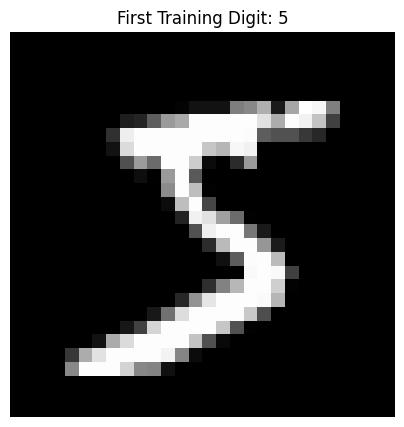

In [2]:
# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training Images Shape:", X_train.shape)
print("Testing Images Shape:", X_test.shape)

plt.figure(figsize=(5, 5))
plt.imshow(X_train[0], cmap="gray")
plt.title("First Training Digit: " + str(y_train[0]))
plt.axis("off")
plt.show()

## 3. Normalize the images

In [3]:
# Normalize pixel values between 0 and 1
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Normalized Image Shape:", X_train[0].shape)
print("Minimum Pixel Value:", X_train[0].min())
print("Maximum Pixel Value:", X_train[0].max())

Normalized Image Shape: (28, 28)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


## 4. Build a simple DNN model

- Flatten: converts the 28 × 28 image into a one-dimensional array.
- Hidden Dense layer: 128 neurons with ReLU activation.
- Output Dense layer: 10 neurons (digits 0–9) with Softmax activation.

In [4]:
# Build a simple DNN model
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

# Display the model architecture
print("DNN Model Summary:")
model.summary()

DNN Model Summary:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Compile and train the model

In [5]:
# Compile the DNN model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training the DNN Model...")

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Training the DNN Model...
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9237 - loss: 0.2692 - val_accuracy: 0.9687 - val_loss: 0.1226
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9655 - loss: 0.1178 - val_accuracy: 0.9732 - val_loss: 0.0947
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9755 - loss: 0.0814 - val_accuracy: 0.9775 - val_loss: 0.0785
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9824 - loss: 0.0597 - val_accuracy: 0.9777 - val_loss: 0.0767
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9852 - loss: 0.0475 - val_accuracy: 0.9787 - val_loss: 0.0769


## 6. Visualize training and validation loss

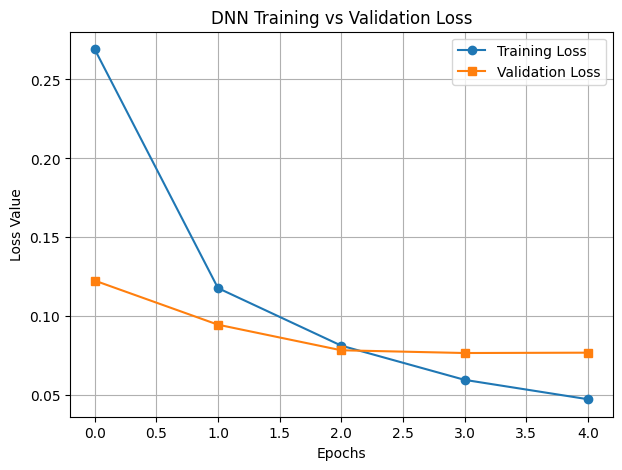

In [6]:
# Plot training and validation loss
plt.figure(figsize=(7, 5))

plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="s", label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss Value")
plt.title("DNN Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 7. Visualize training and validation accuracy

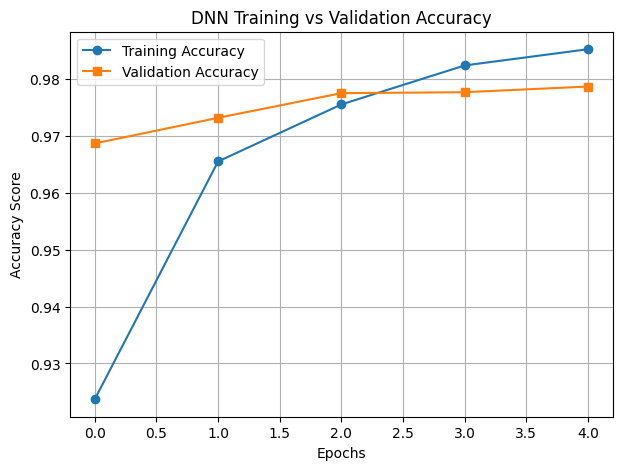

In [7]:
# Plot training and validation accuracy
plt.figure(figsize=(7, 5))

plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="s", label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy Score")
plt.title("DNN Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## 8. Visualize hidden-layer activations

An activation is the output produced by a layer for a given input image. We display the first 16 values from the hidden Dense layer.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


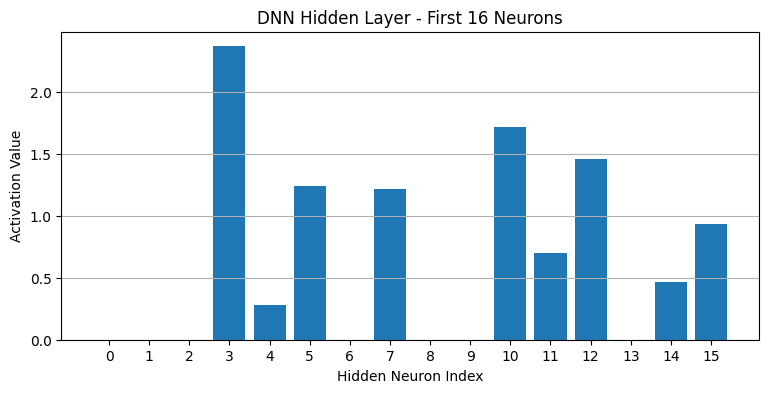

In [8]:
# Visualize hidden-layer activations

activation_model = Model(
    inputs=model.inputs,
    outputs=model.layers[1].output
)

activations = activation_model.predict(X_test[0:1])

plt.figure(figsize=(9, 4))
plt.bar(range(16), activations[0][:16])

plt.xlabel("Hidden Neuron Index")
plt.ylabel("Activation Value")
plt.title("DNN Hidden Layer - First 16 Neurons")
plt.xticks(range(16))
plt.grid(axis="y")
plt.show()

## 9. Predict a digit

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


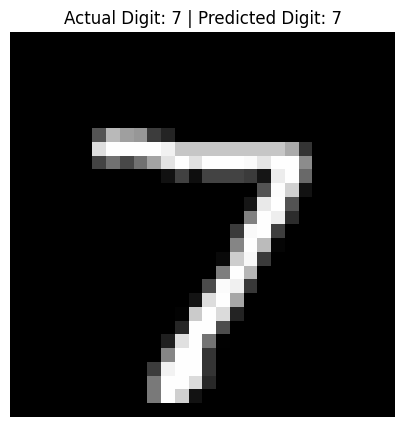

Actual Digit: 7
Predicted Digit: 7


In [9]:
# Predict a digit

prediction = model.predict(X_test[0:1])
predicted_digit = np.argmax(prediction)

plt.figure(figsize=(5, 5))
plt.imshow(X_test[0], cmap="gray")
plt.title("Actual Digit: " + str(y_test[0]) +
          " | Predicted Digit: " + str(predicted_digit))
plt.axis("off")
plt.show()

print("Actual Digit:", y_test[0])
print("Predicted Digit:", predicted_digit)

## 10. Evaluate the model

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9772 - loss: 0.0763
Test Loss: 0.0763
Test Accuracy: 97.72 %


Observations
1. MNIST contains grayscale images of handwritten digits from 0 to 9.
2. The Flatten layer converts each image into a one-dimensional input.
3. The hidden Dense layer learns patterns from the digit images.
4. The output layer has 10 neurons, one for each digit.
5. The loss graph shows how prediction error changes during training.
6. The activation graph displays the output values of selected hidden-layer neurons.
7. Test accuracy indicates how well the model classifies unseen images

Result

A simple Deep Neural Network was successfully built using Keras for handwritten digit classification. Model layers, hidden-layer activations, training loss and accuracy were visualized. The model was evaluated using test data and achieved 97.72% test accuracy with a loss of 0.0763.